# Chapitre 5 - Cours 3 : splines multidimensionnelles, noyaux (RKHS) et ondelettes

Ce dernier notebook de cours couvre la fin du chapitre 5 :

1. splines en dimension $p > 1$ : produits tensoriels et splines de plaque mince (§5.7) ;
2. régularisation et **espaces de Hilbert à noyau reproduisant** (RKHS), présentés pas à
   pas (§5.8, figures 5.13 à 5.15) ;
3. lissage par **ondelettes** de Haar : bases multirésolution, transformée rapide,
   seuillage doux (§5.9, figures 5.16 à 5.19).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch05_splines import (bspline_basis, SmoothingSpline, haar_transform,
                              inverse_haar_transform, haar_matrix, soft_threshold)
set_style()

## 1. Splines multidimensionnelles (§5.7)

**Produit tensoriel.** Si $\{h_{1j}(X_1)\}_{j \le M_1}$ et $\{h_{2k}(X_2)\}_{k \le M_2}$
sont des bases de fonctions d'une variable, les produits (éq. (5.35))

$$
g_{jk}(X) = h_{1j}(X_1)\,h_{2k}(X_2),\qquad j = 1..M_1,\ k = 1..M_2,
$$

forment une base de dimension $M_1 M_2$ pour des fonctions de $X = (X_1, X_2)$ :
$g(X) = \sum_{j,k}\theta_{jk}\,g_{jk}(X)$ (éq. (5.36)). La dimension croît
exponentiellement avec $p$ : c'est une manifestation du *fléau de la dimension*.

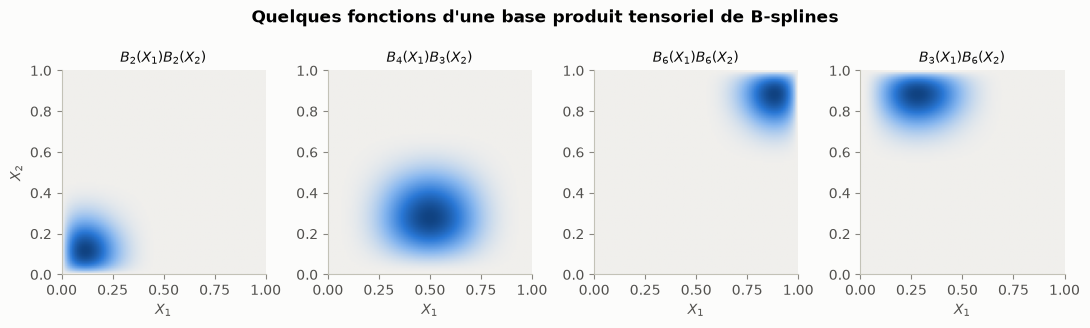

In [2]:
kn = np.linspace(0, 1, 5)[1:-1]
u = np.linspace(0, 1, 120)
B1 = bspline_basis(u, kn, 0, 1)            # 7 B-splines cubiques par axe
paires = [(1, 1), (3, 2), (5, 5), (2, 5)]
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
for ax, (j, k) in zip(axes, paires):
    G = np.outer(B1[:, k], B1[:, j])
    ax.imshow(G, origin="lower", extent=[0, 1, 0, 1], cmap=SEQ)
    ax.set_title("$B_{%d}(X_1)B_{%d}(X_2)$" % (j + 1, k + 1), fontsize=10)
    ax.set_xlabel("$X_1$")
    ax.grid(False)
axes[0].set_ylabel("$X_2$")
fig.suptitle("Quelques fonctions d'une base produit tensoriel de B-splines", fontweight="bold")
plt.tight_layout()
plt.show()

**Splines de plaque mince.** La pénalité $\int f''^2$ se généralise en dimension 2 par
(éq. (5.38))

$$
J[f] = \iint_{\mathbb R^2}\left[\Big(\frac{\partial^2 f}{\partial x_1^2}\Big)^2
 + 2\Big(\frac{\partial^2 f}{\partial x_1\partial x_2}\Big)^2
 + \Big(\frac{\partial^2 f}{\partial x_2^2}\Big)^2\right]dx_1\,dx_2 .
$$

Le minimiseur de $\sum_i\{y_i - f(x_i)\}^2 + \lambda J[f]$ est une **spline de plaque
mince** (éq. (5.39)) :
$f(x) = \beta_0 + \beta^T x + \sum_{j=1}^{N}\alpha_j h_j(x)$ avec
$h_j(x) = \|x - x_j\|^2\log\|x - x_j\|$ (fonctions radiales). Les $\alpha_j$ doivent
vérifier des contraintes linéaires pour que $J[f]$ soit fini (exercice 5.14).

> **Remarque.** Une alternative plus économique est le modèle **additif**
> $f(X) = \alpha + \sum_j f_j(X_j)$ (chapitre 9), avec une pénalité
> $\sum_j\int f_j''^2$ (éq. (5.40)), ou des décompositions ANOVA avec quelques
> interactions (éq. (5.41)).

## 2. Régularisation et noyaux reproduisants (§5.8)

Le cadre général est (éq. (5.42))

$$
\min_{f \in \mathcal H}\ \sum_{i=1}^{N} L(y_i, f(x_i)) + \lambda J(f),
$$

où $L$ est une fonction de perte et $J$ une pénalité. La spline de lissage en est un cas
particulier ($L$ quadratique, $J(f) = \int f''^2$). Nous allons voir une famille de
pénalités pour laquelle ce problème de dimension infinie se ramène, comme pour les
splines, à un problème de dimension $N$.

### Noyaux : définition

Un **noyau** est une fonction $K : \mathbb R^p \times \mathbb R^p \to \mathbb R$
**symétrique** ($K(x, y) = K(y, x)$) et **(semi-)définie positive** : pour tous points
$x_1, \dots, x_n$, la **matrice de Gram** $\mathbf K = (K(x_i, x_j))_{i,j}$ est
semi-définie positive, i.e. $\alpha^T\mathbf K\alpha \ge 0$ pour tout $\alpha$.

Exemples :

- noyau polynomial $K(x, y) = (\langle x, y\rangle + 1)^d$ ;
- noyau gaussien (radial) $K(x, y) = e^{-\nu\|x - y\|^2}$.

> **Intuition.** $K(x, y)$ mesure une **similarité** entre $x$ et $y$. Penser à un
> produit scalaire $\langle h(x), h(y)\rangle$ entre des « caractéristiques » $h(x)$,
> éventuellement en nombre infini.

In [3]:
rng = np.random.RandomState(0)
pts = rng.randn(30, 2)
gauss = lambda A, B, nu=1.0: np.exp(-nu * ((A[:, None, :] - B[None, :, :]) ** 2).sum(-1))
poly = lambda A, B, d=2: (A @ B.T + 1) ** d
for nom, Kf in [("gaussien", gauss), ("polynomial d=2", poly)]:
    Kg = Kf(pts, pts)
    print("noyau %-15s : symétrique %s, plus petite valeur propre = %.2e"
          % (nom, np.allclose(Kg, Kg.T), np.linalg.eigvalsh(Kg).min()))

noyau gaussien        : symétrique True, plus petite valeur propre = 2.09e-06
noyau polynomial d=2  : symétrique True, plus petite valeur propre = -5.04e-14


### Décomposition spectrale d'un noyau

Une matrice symétrique semi-définie positive s'écrit
$\mathbf K = \sum_i \gamma_i v_i v_i^T$ avec $\gamma_i \ge 0$ et $(v_i)$ orthonormée. Le
**théorème de Mercer** est l'analogue pour les fonctions : sous des hypothèses de
régularité, (éq. (5.45))

$$
K(x, y) = \sum_{i=1}^{\infty}\gamma_i\,\phi_i(x)\,\phi_i(y),\qquad \gamma_i \ge 0,
\qquad \sum_i\gamma_i^2 < \infty,
$$

où les fonctions propres $\phi_i$ sont orthonormées (pour un produit scalaire
$\int f g$ pondéré convenable).

**L'espace $\mathcal H_K$.** On considère les fonctions $f = \sum_i c_i\phi_i$ telles que
(éq. (5.46)-(5.47))

$$
\|f\|_{\mathcal H_K}^2 \;\stackrel{\text{déf}}{=}\; \sum_{i=1}^{\infty}\frac{c_i^2}{\gamma_i} < \infty .
$$

C'est un espace de Hilbert (un espace vectoriel muni d'un produit scalaire
$\langle f, g\rangle_{\mathcal H_K} = \sum_i c_i d_i/\gamma_i$, complet). Les fonctions
propres de **petite** valeur propre $\gamma_i$ coûtent **cher** en norme : on les
pénalise davantage. Prendre $J(f) = \|f\|^2_{\mathcal H_K}$ donne (éq. (5.48)-(5.49))

$$
\min_{\{c_j\}}\ \sum_{i=1}^{N} L\Big(y_i, \sum_j c_j\phi_j(x_i)\Big) + \lambda\sum_j\frac{c_j^2}{\gamma_j}.
$$

### Propriété reproduisante et théorème du représentant

Pour $x$ fixé, la fonction $K(\cdot, x) = \sum_i\gamma_i\phi_i(x)\,\phi_i(\cdot)$ a pour
coefficients $c_i = \gamma_i\phi_i(x)$. Pour $f = \sum_i c_i\phi_i$ :

$$
\langle K(\cdot, x), f\rangle_{\mathcal H_K} = \sum_i\frac{\gamma_i\phi_i(x)\,c_i}{\gamma_i}
  = \sum_i c_i\phi_i(x) = f(x).
$$

C'est la **propriété reproduisante** (d'où le nom « RKHS », *reproducing kernel Hilbert
space*) ; en particulier $\langle K(\cdot, x_i), K(\cdot, x_j)\rangle_{\mathcal H_K} =
K(x_i, x_j)$ (exercice 5.15).

**Théorème du représentant.** La solution de (5.48) s'écrit (éq. (5.50))

$$
f(x) = \sum_{i=1}^{N}\alpha_i\,K(x, x_i),
$$

*Idée de preuve* (exercice 5.15) : décomposons $f = g + \rho$ avec $g$ dans
$\mathrm{Vect}\{K(\cdot, x_i)\}$ et $\rho$ orthogonale à cet espace. Alors
$\rho(x_i) = \langle K(\cdot, x_i), \rho\rangle = 0$ : la perte ne voit pas $\rho$, et
$\|f\|^2 = \|g\|^2 + \|\rho\|^2$ (Pythagore) : $\rho$ ne fait qu'augmenter la pénalité.

Pour $f = \sum_i\alpha_i K(\cdot, x_i)$, la propriété reproduisante donne
$J(f) = \sum_{i,j}K(x_i, x_j)\alpha_i\alpha_j = \alpha^T\mathbf K\alpha$ (éq. (5.51)),
et le problème devient de dimension finie (éq. (5.52)) :
$\min_\alpha L(\mathbf y, \mathbf K\alpha) + \lambda\alpha^T\mathbf K\alpha$.

Avec la perte quadratique (éq. (5.54)), le gradient
$-2\mathbf K(\mathbf y - \mathbf K\alpha) + 2\lambda\mathbf K\alpha$ s'annule pour
(éq. (5.55)-(5.57))

$$
\hat\alpha = (\mathbf K + \lambda\mathbf I)^{-1}\mathbf y,\qquad
\hat{\mathbf f} = \mathbf K(\mathbf K + \lambda\mathbf I)^{-1}\mathbf y
  = (\mathbf I + \lambda\mathbf K^{-1})^{-1}\mathbf y ,
$$

à comparer avec la forme de Reinsch $(\mathbf I + \lambda\mathbf K)^{-1}$ des splines de
lissage : ici c'est $\mathbf K^{-1}$ qui joue le rôle de la matrice de pénalité. C'est la
**régression ridge à noyau**.

### Noyau gaussien sur les données « mixture » (figures 5.13 à 5.15)

On utilise la première coordonnée des 200 points d'apprentissage de l'exemple simulé du
chapitre 2, et le noyau gaussien $K(x, y) = e^{-\nu(x - y)^2}$ avec $\nu = 1$. Chaque
fonction $k_m(x) = K(x, x_m)$ est une « bosse » centrée en un point d'apprentissage
(éq. (5.64)).

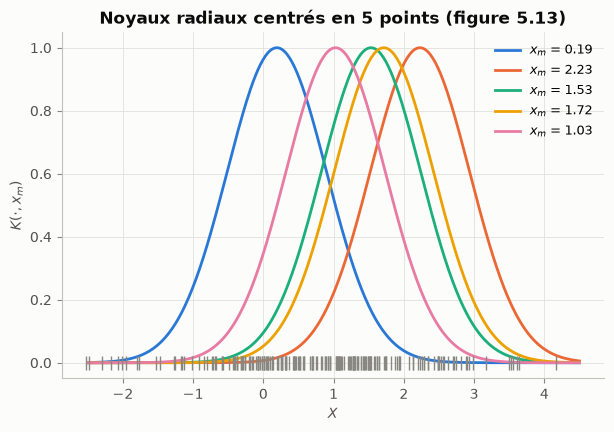

In [4]:
mix = datasets.load_mixture_example()
x1 = np.sort(mix["x"][:, 0])
Kfun = lambda a, b, nu=1.0: np.exp(-nu * (a[:, None] - b[None, :]) ** 2)
grille = np.linspace(-2.5, 4.5, 400)
centres = rng.choice(x1, 5, replace=False)
plt.figure(figsize=(7, 4.5))
for c, xm in zip(COLORS, centres):
    plt.plot(grille, Kfun(grille, np.array([xm]))[:, 0], color=c, label="$x_m$ = %.2f" % xm)
plt.plot(x1, np.zeros_like(x1), "|", color=GRAY, ms=10)
plt.xlabel("$X$")
plt.ylabel(r"$K(\cdot, x_m)$")
plt.title("Noyaux radiaux centrés en 5 points (figure 5.13)")
plt.legend()
plt.show()

Diagonalisons la matrice de Gram $\mathbf K$ ($200 \times 200$) :
$\mathbf K = \Phi\,\mathbf D_\gamma\Phi^T$. Les colonnes de $\Phi$ sont des estimations
des fonctions propres $\phi_\ell$ évaluées aux points $x_i$ (exercice 5.17), et les
$\hat\gamma_\ell$ des estimations des valeurs propres. Les premières fonctions propres
sont lisses, puis de plus en plus oscillantes (figure 5.14, panneau de gauche).

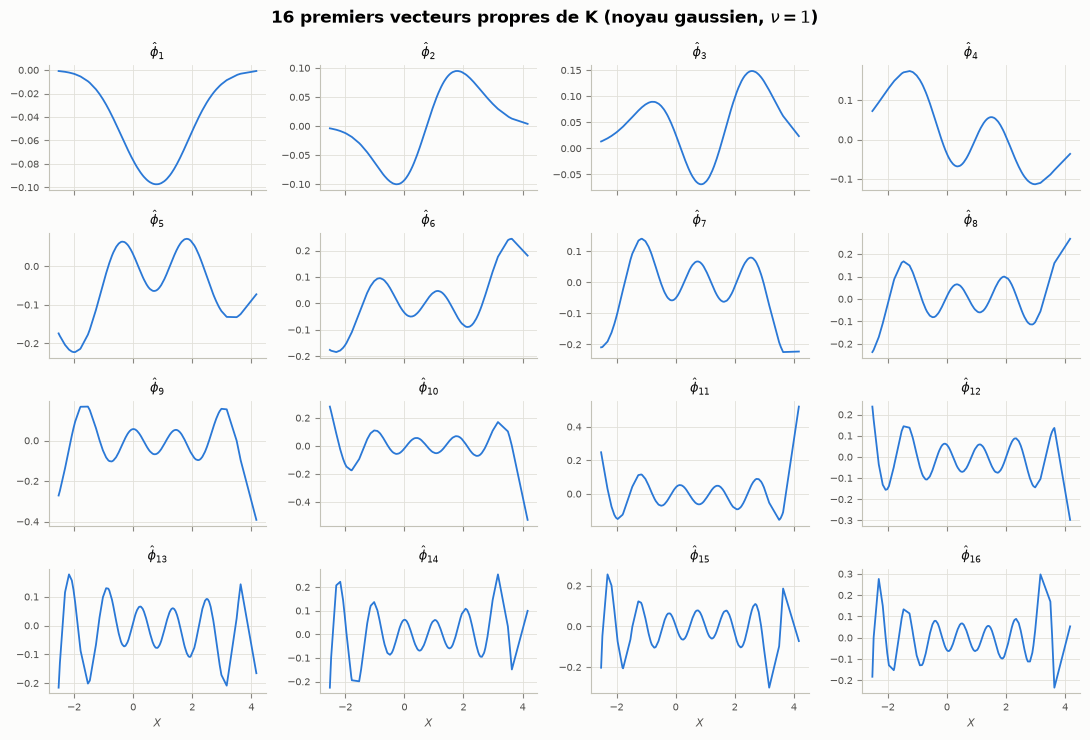

In [5]:
Kmat = Kfun(x1, x1)
gam, Phi = np.linalg.eigh(Kmat)
gam, Phi = gam[::-1], Phi[:, ::-1]
fig, axes = plt.subplots(4, 4, figsize=(11, 7.5), sharex=True)
for l, ax in enumerate(axes.ravel()):
    ax.plot(x1, Phi[:, l], color=BLUE, lw=1.3)
    ax.set_title(r"$\hat\phi_{%d}$" % (l + 1), fontsize=9)
    ax.tick_params(labelsize=7)
fig.suptitle("16 premiers vecteurs propres de $\\mathbf{K}$ (noyau gaussien, $\\nu = 1$)",
             fontweight="bold")
for ax in axes[-1]:
    ax.set_xlabel("$X$", fontsize=8)
plt.tight_layout()
plt.show()

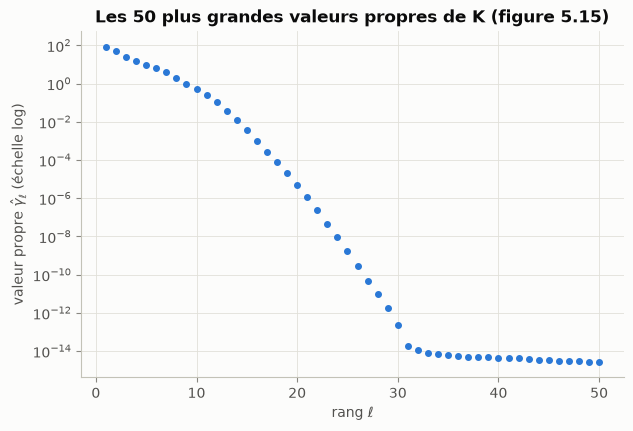

In [6]:
plt.figure(figsize=(7, 4.5))
plt.semilogy(np.arange(1, 51), np.maximum(gam[:50], 1e-16), "o", color=BLUE, ms=4)
plt.xlabel(r"rang $\ell$")
plt.ylabel(r"valeur propre $\hat\gamma_\ell$ (échelle log)")
plt.title("Les 50 plus grandes valeurs propres de $\\mathbf{K}$ (figure 5.15)")
plt.show()

Les valeurs propres décroissent très vite : au-delà de la trentième, elles sont
numériquement nulles. Les « caractéristiques » rééchelonnées
$h_\ell(x) = \sqrt{\hat\gamma_\ell}\,\hat\phi_\ell(x)$ (éq. (5.65)) vérifient
$\langle h(x_i), h(x_{i'})\rangle = K(x_i, x_{i'})$ : bien que l'espace des
caractéristiques soit en principe de dimension infinie, la **dimension effective** est
faible.

In [7]:
Hfeat = Phi * np.sqrt(np.maximum(gam, 0))
print("max |H H^T - K| =", np.abs(Hfeat @ Hfeat.T - Kmat).max())
for lam in [0.01, 0.1, 1.0]:
    print("lambda = %-5g : dimension effective tr(K (K + lambda I)^-1) = %.1f"
          % (lam, np.sum(gam / (gam + lam))))

max |H H^T - K| = 1.6209256159527285e-14
lambda = 0.01  : dimension effective tr(K (K + lambda I)^-1) = 13.6
lambda = 0.1   : dimension effective tr(K (K + lambda I)^-1) = 11.3
lambda = 1     : dimension effective tr(K (K + lambda I)^-1) = 8.3


### Régression ridge à noyau sur la simulation (5.22)

Comparons la régression ridge à noyau gaussien ($\nu = 30$ sur $[0, 1]$) à la spline
de lissage, chacune avec un paramètre choisi par validation croisée « leave-one-out ».
Comme $\hat{\mathbf f} = \mathbf S\mathbf y$ avec $\mathbf S = \mathbf K(\mathbf K +
\lambda\mathbf I)^{-1}$ symétrique, la formule (5.27) s'applique aussi.

In [8]:
rng = np.random.RandomState(1)
N = 100
xs = np.sort(rng.uniform(0, 1, N))
fsim = lambda t: np.sin(12 * (t + 0.2)) / (t + 0.2)
ys = fsim(xs) + rng.randn(N)
Ks = Kfun(xs, xs, nu=30.0)

def loo_noyau(lam):
    Sk = Ks @ np.linalg.inv(Ks + lam * np.eye(N))
    return np.mean(((ys - Sk @ ys) / (1 - np.diag(Sk))) ** 2)

lams = np.logspace(-4, 1, 40)
cv_k = [loo_noyau(l) for l in lams]
lam_k = lams[np.argmin(cv_k)]
alpha = np.linalg.solve(Ks + lam_k * np.eye(N), ys)
print("lambda (noyau) choisi : %.4f, ddl effectifs = %.1f"
      % (lam_k, np.trace(Ks @ np.linalg.inv(Ks + lam_k * np.eye(N)))))

lambda (noyau) choisi : 0.2154, ddl effectifs = 8.6


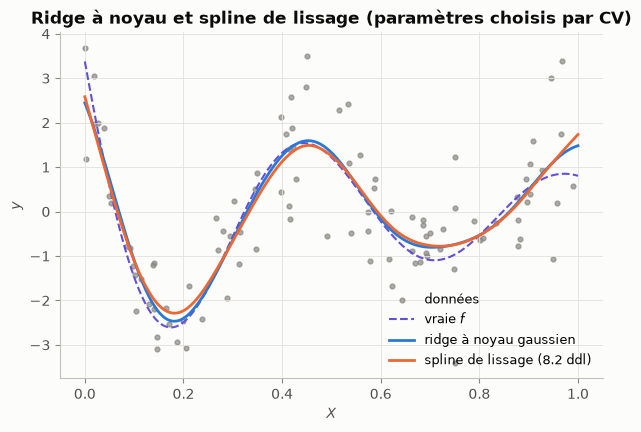

In [9]:
ss = SmoothingSpline(lam=1.0).fit(xs, ys)
cv_s = []
for d in np.linspace(4, 15, 45):
    lam_d = SmoothingSpline(df=d).fit(xs, ys).lam_
    ss.set_lambda(lam_d)
    Sm = ss.smoother_matrix()
    cv_s.append((np.mean(((ys - Sm @ ys) / (1 - np.diag(Sm))) ** 2), lam_d))
ss.set_lambda(min(cv_s)[1])
gx = np.linspace(0, 1, 300)
plt.figure(figsize=(7, 4.5))
plt.scatter(xs, ys, s=12, color=GRAY, alpha=0.7, label="données")
plt.plot(gx, fsim(gx), color=COLORS[6], lw=1.5, ls="--", label="vraie $f$")
plt.plot(gx, Kfun(gx, xs, nu=30.0) @ alpha, color=BLUE, label="ridge à noyau gaussien")
plt.plot(gx, ss.predict(gx), color=ORANGE, label="spline de lissage (%.1f ddl)" % ss.df_)
plt.xlabel("$X$")
plt.ylabel("$y$")
plt.title("Ridge à noyau et spline de lissage (paramètres choisis par CV)")
plt.legend()
plt.show()

> **Remarque (noyau polynomial).** Pour $K(x, y) = (\langle x, y\rangle + 1)^d$ sur
> $\mathbb R^p$, l'espace engendré est celui des polynômes de degré total $\le d$, de
> dimension $M = \binom{p+d}{d}$, et $K(x, y) = \sum_m h_m(x)h_m(y)$ avec par exemple
> $h(x) = (1, \sqrt2 x_1, \sqrt2 x_2, x_1^2, x_2^2, \sqrt2 x_1x_2)$ pour $p = d = 2$
> (éq. (5.59)-(5.61)). La ridge à noyau ne calcule que $N^2$ valeurs du noyau, quel que
> soit $M$ (exercice 5.16). De même, les **machines à vecteurs de support** (chapitre 12)
> minimisent $\sum_i[1 - y_if(x_i)]_+ + \frac\lambda2\alpha^T\mathbf K\alpha$ (éq. (5.67)).

In [10]:
xa, xb = rng.randn(2), rng.randn(2)
h = lambda v: np.array([1, np.sqrt(2) * v[0], np.sqrt(2) * v[1], v[0] ** 2, v[1] ** 2,
                        np.sqrt(2) * v[0] * v[1]])
print("K(x, y) = %.6f ; <h(x), h(y)> = %.6f" % ((xa @ xb + 1) ** 2, h(xa) @ h(xb)))

K(x, y) = 1.261500 ; <h(x), h(y)> = 1.261500


## 3. Lissage par ondelettes (§5.9)

Avec les splines de régression, on **sélectionne** quelques fonctions de base ; avec les
splines de lissage, on garde une base complète mais on **rétrécit** les coefficients vers
la régularité. Les ondelettes utilisent une base orthonormée complète, puis
**rétrécissent et sélectionnent** : on vise une représentation **parcimonieuse**. Une
fonction presque plate avec quelques bosses isolées se représente avec peu d'ondelettes :
elles sont localisées **en temps et en fréquence**.

### La base de Haar

- **Fonction d'échelle** (« père ») : $\phi(x) = \mathbf 1_{[0,1)}(x)$. Les translatées
  $\phi_{0,k}(x) = \phi(x - k)$ engendrent l'espace $V_0$ des fonctions constantes sur
  les intervalles $[k, k+1)$.
- Plus généralement $\phi_{j,k}(x) = 2^{j/2}\phi(2^jx - k)$ engendre $V_j$ (fonctions
  constantes sur les intervalles de longueur $2^{-j}$) ; on a
  $\dots \subset V_{-1} \subset V_0 \subset V_1 \subset \dots$
- **Ondelette** (« mère ») : $\psi(x) = \phi(2x) - \phi(2x - 1)$, qui vaut $+1$ sur
  $[0, \frac12)$ et $-1$ sur $[\frac12, 1)$. Les $\psi_{j,k}(x) = 2^{j/2}\psi(2^jx - k)$
  engendrent l'espace $W_j$, **complément orthogonal** de $V_j$ dans $V_{j+1}$ :
  $V_{j+1} = V_j \oplus W_j$.

En itérant : $V_J = V_0 \oplus W_0 \oplus W_1 \oplus \dots \oplus W_{J-1}$. Sur une grille
de $N = 2^J$ points, cela donne $1 + (1 + 2 + \dots + 2^{J-1}) = 2^J$ fonctions
orthonormées.

W^T W = I : True


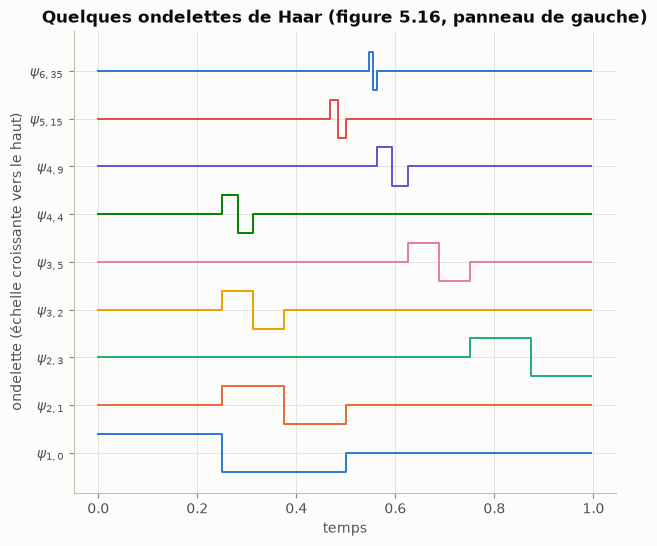

In [11]:
Nh = 256
W = haar_matrix(Nh)
print("W^T W = I :", np.allclose(W.T @ W, np.eye(Nh)))
temps = np.arange(Nh) / Nh
choix = [(1, 0), (2, 1), (2, 3), (3, 2), (3, 5), (4, 4), (4, 9), (5, 15), (6, 35)]
plt.figure(figsize=(7, 6))
for r, (j, k) in enumerate(choix):
    col = 2 ** j + k
    plt.step(temps, r + 0.4 * W[:, col] / np.abs(W[:, col]).max(), where="post",
             color=COLORS[r % len(COLORS)], lw=1.4)
plt.yticks(range(len(choix)), [r"$\psi_{%d,%d}$" % jk for jk in choix])
plt.xlabel("temps")
plt.ylabel("ondelette (échelle croissante vers le haut)")
plt.title("Quelques ondelettes de Haar (figure 5.16, panneau de gauche)")
plt.show()

> **Remarque.** Les ondelettes de Haar sont simples mais peu régulières (discontinues).
> Les ondelettes **symmlet-$p$** de Daubechies, utilisées dans le livre, sont plus lisses
> et ont $p$ **moments nuls** : $\int\psi(x)x^j\,dx = 0$ pour $j = 0, \dots, p-1$ ;
> les polynômes de degré $< p$ sont alors représentés exactement dans $V_0$
> (exercice 5.18). Haar a un seul moment nul ($\int\psi = 0$).

### Transformée en ondelettes rapide

Si $\mathbf W$ est la matrice $N \times N$ (orthogonale) des ondelettes évaluées sur la
grille, la **transformée en ondelettes** de $\mathbf y$ est $\mathbf y^* = \mathbf
W^T\mathbf y$ : ce sont aussi les coefficients des moindres carrés, puisque
$(\mathbf W^T\mathbf W)^{-1}\mathbf W^T\mathbf y = \mathbf W^T\mathbf y$.

Le produit matriciel coûte $O(N^2)$, mais un **algorithme pyramidal** fait le calcul en
$O(N)$ (exercice 5.19) : à chaque étage, on remplace le signal courant $a$ de longueur $n$
par ses moyennes $(a_{2i} + a_{2i+1})/\sqrt2$ et ses différences
$(a_{2i} - a_{2i+1})/\sqrt2$, de longueur $n/2$ chacune ; le coût total est
$N + N/2 + N/4 + \dots \le 2N$.

In [12]:
import time

def chrono(fonction, repet=20):
    """Durée médiane (en secondes) d'un appel à fonction()."""
    durees = []
    for _ in range(repet):
        t0 = time.perf_counter()
        fonction()
        durees.append(time.perf_counter() - t0)
    return np.median(durees)

for J in [8, 10, 12]:
    n = 2 ** J
    v = rng.randn(n)
    Wn = haar_matrix(n)
    tp = chrono(lambda: haar_transform(v))
    tm = chrono(lambda: Wn.T @ v)
    print("N = %5d : pyramide %.1e s (~%d opérations), produit W^T y %.1e s (%d opérations), "
          "écart %.0e" % (n, tp, 2 * n, tm, n * n, np.abs(haar_transform(v) - Wn.T @ v).max()))

N =   256 : pyramide 2.3e-05 s (~512 opérations), produit W^T y 5.0e-06 s (65536 opérations), écart 4e-16
N =  1024 : pyramide 3.0e-05 s (~2048 opérations), produit W^T y 8.9e-05 s (1048576 opérations), écart 9e-16


N =  4096 : pyramide 3.8e-05 s (~8192 opérations), produit W^T y 2.6e-03 s (16777216 opérations), écart 2e-15


### Débruitage par seuillage doux (SURE shrinkage)

On considère le critère (éq. (5.68)) $\min_\theta \|\mathbf y - \mathbf W\theta\|_2^2 +
2\lambda\|\theta\|_1$, qui est un **lasso** (chapitre 3). Comme $\mathbf W$ est
orthogonale, $\|\mathbf y - \mathbf W\theta\|^2 = \|\mathbf W^T\mathbf y - \theta\|^2 =
\sum_j (y_j^* - \theta_j)^2$ : le problème se sépare en $N$ problèmes à une variable
$\min_{\theta_j}(y_j^* - \theta_j)^2 + 2\lambda|\theta_j|$, dont la solution est le
**seuillage doux** (éq. (5.69))

$$
\hat\theta_j = \mathrm{sign}(y_j^*)\,(|y_j^*| - \lambda)_+ .
$$

*Justification.* Pour $\theta_j > 0$ la dérivée $2(\theta_j - y_j^*) + 2\lambda$
s'annule en $y_j^* - \lambda$, admissible si $y_j^* > \lambda$ ; de même pour
$\theta_j < 0$ ; sinon le minimum est en $0$. Puis $\hat{\mathbf f} = \mathbf W\hat\theta$.

**Choix du seuil.** Si $\mathbf y$ est un bruit blanc $\mathcal N(0, \sigma^2\mathbf I)$,
alors $\mathbf y^* = \mathbf W^T\mathbf y$ aussi (transformation orthogonale), et le
maximum de $N$ variables $|Z_j|$ i.i.d. $\mathcal N(0, \sigma^2)$ est de l'ordre de
$\sigma\sqrt{2\log N}$. On prend donc $\lambda = \sigma\sqrt{2\log N}$ : les coefficients
en dessous sont probablement du bruit. $\sigma$ s'estime sur les coefficients du niveau
le plus fin, presque purement du bruit : $\hat\sigma = \mathrm{médiane}(|y^*_j|)/0{,}6745$.

In [13]:
max_obs = [np.abs(np.random.RandomState(s).randn(1024)).max() for s in range(200)]
print("moyenne du max de 1024 |N(0,1)| : %.2f ; sqrt(2 log 1024) = %.2f"
      % (np.mean(max_obs), np.sqrt(2 * np.log(1024))))

moyenne du max de 1024 |N(0,1)| : 3.43 ; sqrt(2 log 1024) = 3.72


Le signal RMN du livre n'étant pas disponible, nous simulons un signal de même nature
(paliers et sauts isolés, $N = 1024$) auquel on ajoute un bruit $\mathcal N(0, 1)$.

In [14]:
rng = np.random.RandomState(0)
N = 1024
t = np.arange(N) / N
sauts = [0.10, 0.13, 0.15, 0.23, 0.25, 0.40, 0.44, 0.65, 0.76, 0.78, 0.81]
hauteurs = [4, -5, 3, -4, 5, -4.2, 2.1, 4.3, -3.1, 2.1, -4.2]
f_blocs = sum(h * (t >= s) for s, h in zip(sauts, hauteurs))
f_blocs = 7 * f_blocs / f_blocs.std()
y_blocs = f_blocs + rng.randn(N)

In [15]:
def debruite_haar(y, j0=4):
    """Seuillage doux des coefficients de Haar au-delà du niveau j0 (V_{j0} conservé)."""
    c = haar_transform(y)
    n = len(y)
    sigma = np.median(np.abs(c[n // 2:])) / 0.6745
    lam = sigma * np.sqrt(2 * np.log(n))
    ct = c.copy()
    ct[2 ** j0:] = soft_threshold(c[2 ** j0:], lam)
    return inverse_haar_transform(ct), c, ct, lam

fw, c_brut, c_seuil, lam_w = debruite_haar(y_blocs)
print("seuil lambda = %.2f ; coefficients non nuls : %d / %d"
      % (lam_w, np.sum(c_seuil != 0), N))

seuil lambda = 3.41 ; coefficients non nuls : 62 / 1024


Représentation des coefficients par niveau (comme la figure 5.17) : chaque ligne est un
niveau $j$ (de $V_4$ en bas jusqu'à $W_9$ en haut) ; un segment vertical de hauteur
proportionnelle à $y^*_{j,k}$ est placé à la position $k/2^j$.

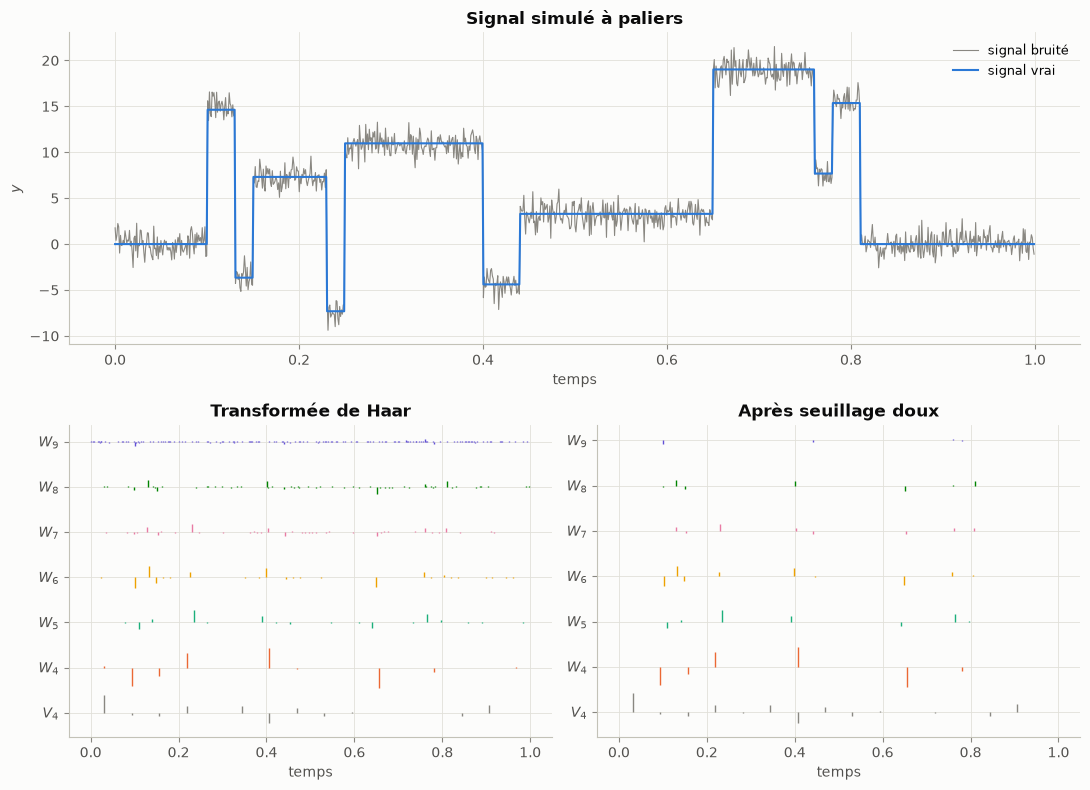

In [16]:
def trace_coeffs(ax, c, titre, j0=4):
    n = len(c)
    J = int(np.log2(n))
    echelle = 0.45 / np.abs(c[2 ** j0:]).max()
    niveaux = list(range(j0, J))
    pos = (np.arange(2 ** j0) + 0.5) / 2 ** j0
    ax.vlines(pos, 0, echelle * c[:2 ** j0] / 4, color=GRAY, lw=1)
    for r, j in enumerate(niveaux, start=1):
        cj = c[2 ** j:2 ** (j + 1)]
        pos = (np.arange(2 ** j) + 0.5) / 2 ** j
        ax.vlines(pos, r, r + echelle * cj, color=COLORS[r % len(COLORS)], lw=1)
    ax.set_yticks(range(len(niveaux) + 1))
    ax.set_yticklabels(["$V_{%d}$" % j0] + ["$W_{%d}$" % j for j in niveaux])
    ax.set_xlabel("temps")
    ax.set_title(titre)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(2, 1, 1)
ax.plot(t, y_blocs, color=GRAY, lw=0.8, label="signal bruité")
ax.plot(t, f_blocs, color=BLUE, lw=1.5, label="signal vrai")
ax.set_xlabel("temps")
ax.set_ylabel("$y$")
ax.set_title("Signal simulé à paliers")
ax.legend()
trace_coeffs(fig.add_subplot(2, 2, 3), c_brut, "Transformée de Haar")
trace_coeffs(fig.add_subplot(2, 2, 4), c_seuil, "Après seuillage doux")
plt.tight_layout()
plt.show()

Comparons au lissage par spline de lissage avec $\lambda$ choisi par validation croisée
généralisée (GCV), comme dans la figure 5.19, sur deux exemples : le signal à paliers et
une fonction régulière (5.22) très bruitée.

In [17]:
def spline_gcv(x, y, lams):
    s = SmoothingSpline(lam=1.0).fit(x, y)
    best = None
    for l in lams:
        s.set_lambda(l)
        g = np.mean(((y - s.predict(x)) / (1 - s.df_ / len(y))) ** 2)
        if best is None or g < best[0]:
            best = (g, l)
    return s.set_lambda(best[1])

sp_blocs = spline_gcv(t, y_blocs, np.logspace(-14, -4, 50))

rng = np.random.RandomState(2)
N2 = 256
t2 = np.arange(N2) / N2
f_lisse = fsim(t2)
y_lisse = f_lisse + 1.0 * rng.randn(N2)
fw2 = debruite_haar(y_lisse, j0=3)[0]
sp_lisse = spline_gcv(t2, y_lisse, np.logspace(-9, -2, 50))

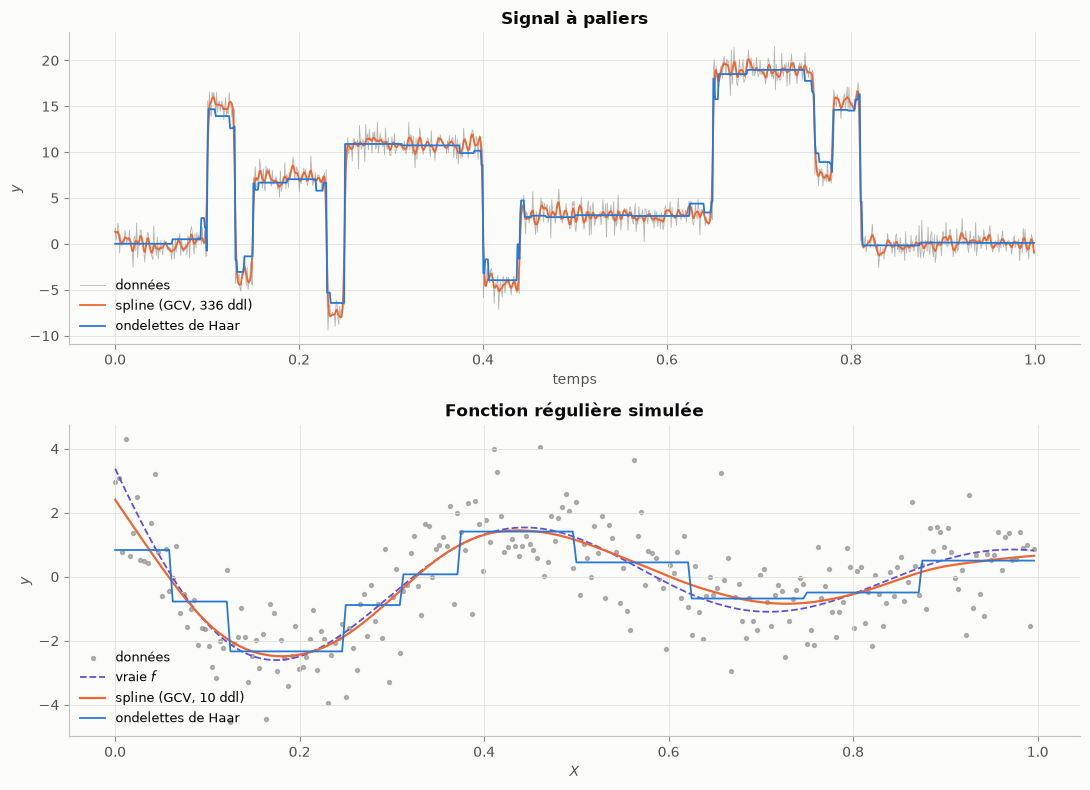

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8))
ax = axes[0]
ax.plot(t, y_blocs, color=GRAY, lw=0.6, alpha=0.6, label="données")
ax.plot(t, sp_blocs.predict(t), color=ORANGE, lw=1.3,
        label="spline (GCV, %.0f ddl)" % sp_blocs.df_)
ax.plot(t, fw, color=BLUE, lw=1.3, label="ondelettes de Haar")
ax.set_title("Signal à paliers")
ax.set_xlabel("temps")
ax.set_ylabel("$y$")
ax.legend(loc="lower left")
ax = axes[1]
ax.scatter(t2, y_lisse, s=8, color=GRAY, alpha=0.6, label="données")
ax.plot(t2, f_lisse, color=COLORS[6], lw=1.3, ls="--", label="vraie $f$")
ax.plot(t2, sp_lisse.predict(t2), color=ORANGE, lw=1.6,
        label="spline (GCV, %.0f ddl)" % sp_lisse.df_)
ax.plot(t2, fw2, color=BLUE, lw=1.3, label="ondelettes de Haar")
ax.set_title("Fonction régulière simulée")
ax.set_xlabel("$X$")
ax.set_ylabel("$y$")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

In [19]:
print("erreur quadratique moyenne par rapport au vrai signal :")
print("  paliers  : spline %.3f | Haar %.3f" % (np.mean((sp_blocs.predict(t) - f_blocs) ** 2),
                                                np.mean((fw - f_blocs) ** 2)))
print("  régulier : spline %.3f | Haar %.3f" % (np.mean((sp_lisse.predict(t2) - f_lisse) ** 2),
                                                np.mean((fw2 - f_lisse) ** 2)))

erreur quadratique moyenne par rapport au vrai signal :
  paliers  : spline 0.771 | Haar 0.602
  régulier : spline 0.047 | Haar 0.253


Sur le signal à paliers, la spline doit introduire des oscillations **partout** pour
suivre les sauts ; les ondelettes localisent les détails là où ils sont. Sur la fonction
régulière très bruitée, c'est l'inverse : la spline gagne, les ondelettes (surtout celles
de Haar, constantes par morceaux) laissent passer des marches inutiles - le prix en
variance de leur adaptativité.

Comparons enfin les deux critères :

- spline : $\min_\theta\|\mathbf y - \mathbf U\theta\|^2 + \lambda\theta^T\mathbf D\theta$
  (éq. (5.21)) - base orthonormée fixe, pénalité quadratique : **rétrécissement**
  différentiel, pas de sélection ;
- ondelettes : $\min_\theta\|\mathbf y - \mathbf W\theta\|^2 + 2\lambda\|\theta\|_1$ -
  base orthonormée localisée, pénalité $L_1$ : **rétrécissement et sélection**.

> **À retenir.**
> - Produits tensoriels et splines de plaque mince étendent les splines à $p > 1$.
> - Pénaliser par la norme d'un RKHS ramène un problème de dimension infinie à $N$
>   coefficients : $f = \sum_i\alpha_iK(\cdot, x_i)$, $\hat\alpha = (\mathbf K +
>   \lambda\mathbf I)^{-1}\mathbf y$ pour la perte quadratique.
> - Les ondelettes donnent une base orthonormée multirésolution ; la transformée se
>   calcule en $O(N)$ et le débruitage se fait par seuillage doux avec
>   $\lambda = \hat\sigma\sqrt{2\log N}$.
> - Splines : régularité ; ondelettes : parcimonie.